# Decision tree

One decision tree for predicting log nitrate (regression) and predicting the chance a sample is over the 10 mg/L limit (classification).

It uses the merged dataset with the 50 selected features and the shared 10 km spatial folds 0 to 3. Fold 4 is the final holdout

## 0. Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
root = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.dummy import DummyRegressor
from sklearn.dummy import DummyClassifier
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import brier_score_loss
from src.features.preprocessing import load_model_data
from src.evaluation import splits
from src.evaluation.make_splits import load_split

In [2]:
# merged team dataset, only the 50 selected features
x, nitrate, meta = load_model_data(log_target=False)
features = list(x.columns)

data = pd.concat([meta, x], axis=1)
data["log_nitrate"] = np.log1p(nitrate)
data["over_10"] = (nitrate > 10).astype(int) # 1 if over the drinking water limit
data = load_split(data) # adds the shared fold for each well

# folds 0-3 for training and testing, fold 4 is the final holdout
train_val = data[~data["holdout"]].reset_index(drop=True)
x_tv = train_val[features]
y_tv = train_val["log_nitrate"]
over_tv = train_val["over_10"]
folds = train_val["fold"]

print(len(train_val), "samples from", train_val["gm_well_id"].nunique(), "wells,", len(features), "features")
print("samples per fold:", folds.value_counts().sort_index().to_dict())
print("share over 10 mg/L:", round(over_tv.mean(), 3))

4191 samples from 1593 wells, 50 features
samples per fold: {0: 1035, 1: 972, 2: 1143, 3: 1041}
share over 10 mg/L: 0.337


## 1. Regression: log nitrate

best depth: 3


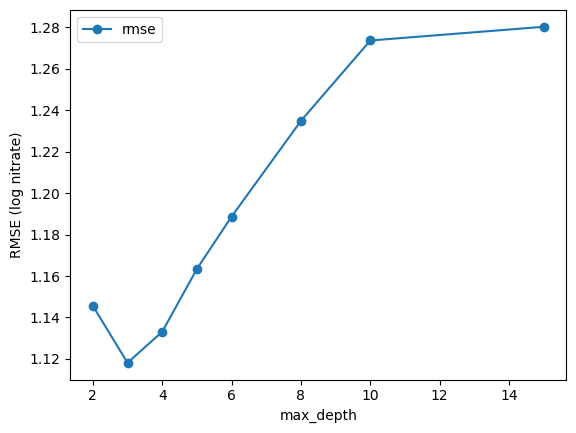

,max_depth,rmse,r2
0,2,1.146,0.139
1,3,1.118,0.180
2,4,1.133,0.158
3,5,1.163,0.112
4,6,1.189,0.073
5,8,1.235,-0.000
6,10,1.274,-0.064
7,15,1.280,-0.075


In [3]:
depths = [2, 3, 4, 5, 6, 8, 10, 15]
search = []

for depth in depths:
    pred = np.zeros(len(train_val))
    for train, test in splits.iter_folds(folds):
        tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=0)
        tree.fit(x_tv[train], y_tv[train])
        pred[test] = tree.predict(x_tv[test])
    search.append({"max_depth": depth, "rmse": root_mean_squared_error(y_tv, pred), "r2": r2_score(y_tv, pred)})

search = pd.DataFrame(search)
best_depth = int(search.loc[search["rmse"].idxmin(), "max_depth"])
print("best depth:", best_depth)

search.plot(x="max_depth", y="rmse", marker="o")
plt.ylabel("RMSE (log nitrate)")
plt.show()
search.round(3)

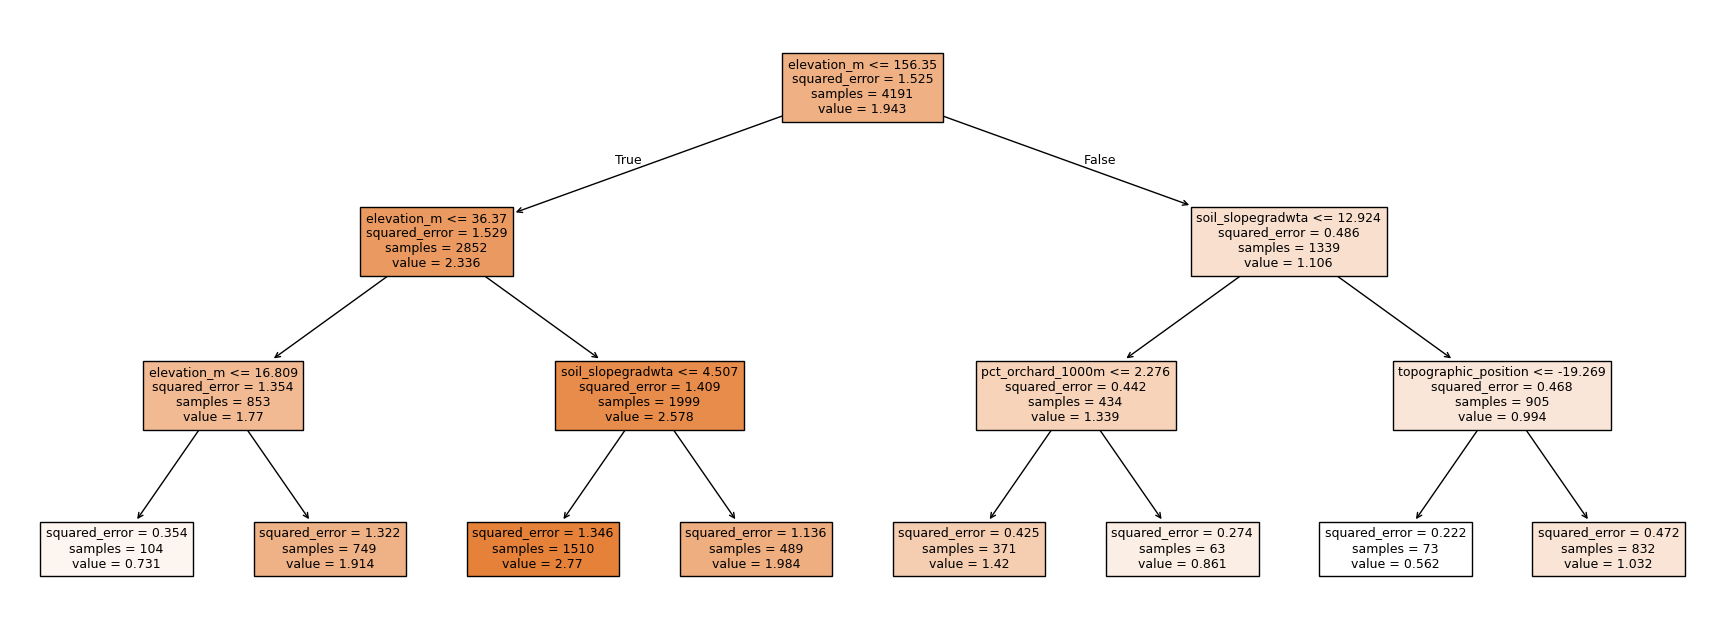

In [4]:
tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=0)
tree.fit(x_tv, y_tv)

plt.figure(figsize=(22, 8))
plot_tree(tree, feature_names=features, filled=True, fontsize=9)
plt.show()

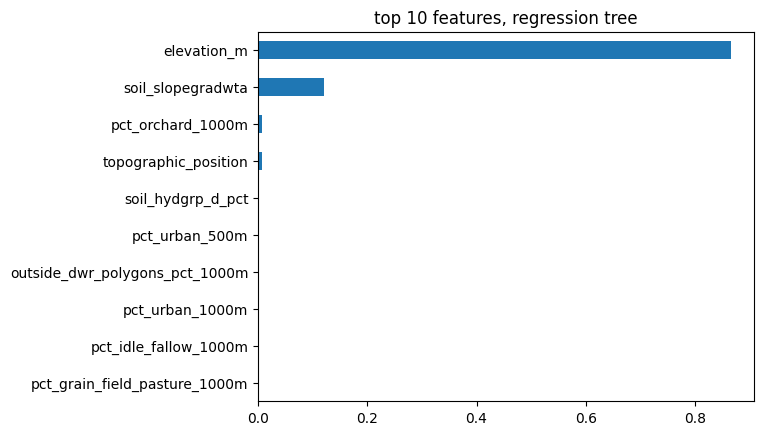

In [5]:
importance = pd.Series(tree.feature_importances_, index=features).sort_values()
importance.tail(10).plot.barh()
plt.title("top 10 features, regression tree")
plt.show()

## 2. Classification: over 10 mg/L

In [6]:
search_clf = []
probs = {} # out-of-fold probabilities for each depth

for depth in depths:
    prob = np.zeros(len(train_val))
    for train, test in splits.iter_folds(folds):
        tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=0)
        tree.fit(x_tv[train], over_tv[train])
        prob[test] = tree.predict_proba(x_tv[test])[:, 1]
    probs[depth] = prob
    search_clf.append({"max_depth": depth, "auc": roc_auc_score(over_tv, prob)})

search_clf = pd.DataFrame(search_clf)
best_depth_clf = int(search_clf.loc[search_clf["auc"].idxmax(), "max_depth"])
prob_tree = probs[best_depth_clf]
print("best depth:", best_depth_clf)
search_clf.round(3)

best depth: 6


,max_depth,auc
0,2,0.723
1,3,0.729
2,4,0.760
3,5,0.759
4,6,0.761
5,8,0.739
6,10,0.725
7,15,0.718


In [7]:
# risk levels: Low < 25%, Moderate 25-50%, High > 50%
risk = np.where(prob_tree < 0.25, "Low", np.where(prob_tree <= 0.5, "Moderate", "High"))
levels = pd.DataFrame({"risk": risk, "over_10": over_tv})

risk_table = levels.groupby("risk")["over_10"].agg(["size", "mean"]).reindex(["Low", "Moderate", "High"])
risk_table.columns = ["samples", "share actually over 10"]
risk_table.round(2)

,samples,share actually over 10
risk,,
Low,1906,0.14
Moderate,755,0.39
High,1530,0.56


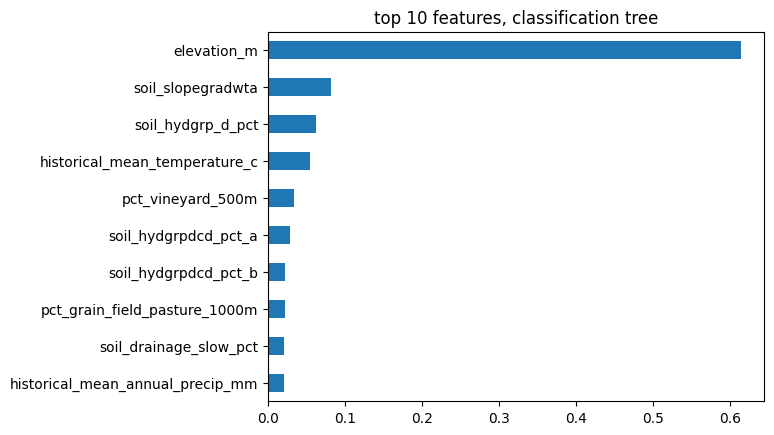

In [8]:
tree_clf = DecisionTreeClassifier(max_depth=best_depth_clf, min_samples_leaf=20, random_state=0)
tree_clf.fit(x_tv, over_tv)

importance_clf = pd.Series(tree_clf.feature_importances_, index=features).sort_values()
importance_clf.tail(10).plot.barh()
plt.title("top 10 features, classification tree")
plt.show()

## 3. Results summary

Baselines: DummyRegressor always guesses the training mean, DummyClassifier always guesses the training share over 10 mg/L.

Brier skill score = 1 - Brier(tree) / Brier(baseline), where Brier is the mean squared error of the probabilities. 0 is no better than the baseline, 1 is perfect.

In [9]:
# baselines, same folds as the trees
pred_dummy = np.zeros(len(train_val))
prob_dummy = np.zeros(len(train_val))

for train, test in splits.iter_folds(folds):
    dummy_reg = DummyRegressor(strategy="mean")
    dummy_reg.fit(x_tv[train], y_tv[train])
    pred_dummy[test] = dummy_reg.predict(x_tv[test])

    dummy_clf = DummyClassifier(strategy="prior")
    dummy_clf.fit(x_tv[train], over_tv[train])
    prob_dummy[test] = dummy_clf.predict_proba(x_tv[test])[:, 1]

In [10]:
best_reg = search[search["max_depth"] == best_depth].iloc[0]
best_clf = search_clf[search_clf["max_depth"] == best_depth_clf].iloc[0]
brier_skill = 1 - brier_score_loss(over_tv, prob_tree) / brier_score_loss(over_tv, prob_dummy)

print(f"dummy regressor: RMSE {root_mean_squared_error(y_tv, pred_dummy):.3f}, R2 {r2_score(y_tv, pred_dummy):.3f}")
print(f"regression tree (depth {best_depth}): RMSE {best_reg['rmse']:.3f}, R2 {best_reg['r2']:.3f}")
print(f"dummy classifier: AUC {roc_auc_score(over_tv, prob_dummy):.3f}, Brier skill score 0")
print(f"classification tree (depth {best_depth_clf}): AUC {best_clf['auc']:.3f}, Brier skill score {brier_skill:.3f}")

dummy regressor: RMSE 1.238, R2 -0.005
regression tree (depth 3): RMSE 1.118, R2 0.180
dummy classifier: AUC 0.491, Brier skill score 0
classification tree (depth 6): AUC 0.761, Brier skill score 0.116


## 4. Swapping elevation for the aquifer subbasin

The trees above lean almost entirely on elevation. That predicts fine, but it is a poor answer for someone asking about their own land, since elevation is just standing in for where the well sits in the valley.

Here elevation is replaced by the groundwater subbasin each well is in (DWR Bulletin 118). The subbasin says which aquifer the well draws from, for example the 180/400 Foot Aquifer near the coast, which sits under a clay layer.

In [11]:
# which subbasin each well is in, wells in the hills outside the basin get "Outside Basin"
basins = gpd.read_file("salinas_valley_subbasins.geojson")
points = gpd.points_from_xy(train_val["gm_longitude"], train_val["gm_latitude"])
wells = gpd.GeoDataFrame(train_val[["gm_well_id"]], geometry=points, crs=4326)
wells = gpd.sjoin(wells, basins[["Basin_Subbasin_Name", "geometry"]], how="left", predicate="within")

train_val["subbasin"] = wells["Basin_Subbasin_Name"].str.replace("SALINAS VALLEY - ", "").fillna("OUTSIDE BASIN").str.title()

by_subbasin = train_val.groupby("subbasin")["over_10"].agg(["size", "mean"]).sort_values("mean")
by_subbasin.columns = ["samples", "share over 10"]
by_subbasin.round(2)

,samples,share over 10
subbasin,,
Outside Basin,310,0.02
Paso Robles Area,686,0.02
Atascadero Area,238,0.09
Monterey,16,0.19
180/400 Foot Aquifer,832,0.26
Upper Valley Aquifer,492,0.47
Forebay Aquifer,952,0.53
East Side Aquifer,665,0.62


In [12]:
# one 0/1 column per subbasin, and no elevation
subbasin_cols = pd.get_dummies(train_val["subbasin"], prefix="sub", dtype=int)
x_sub = pd.concat([x_tv.drop(columns="elevation_m"), subbasin_cols], axis=1)

search_sub = []
for depth in depths:
    pred = np.zeros(len(train_val))
    prob = np.zeros(len(train_val))
    for train, test in splits.iter_folds(folds):
        reg = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=0)
        reg.fit(x_sub[train], y_tv[train])
        pred[test] = reg.predict(x_sub[test])

        clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=0)
        clf.fit(x_sub[train], over_tv[train])
        prob[test] = clf.predict_proba(x_sub[test])[:, 1]
    search_sub.append({"max_depth": depth, "rmse": root_mean_squared_error(y_tv, pred), "r2": r2_score(y_tv, pred), "auc": roc_auc_score(over_tv, prob)})

search_sub = pd.DataFrame(search_sub)
best_reg_sub = search_sub.loc[search_sub["rmse"].idxmin()]
best_clf_sub = search_sub.loc[search_sub["auc"].idxmax()]
best_depth_sub = int(best_clf_sub["max_depth"])

print(f"with elevation: RMSE {best_reg['rmse']:.3f}, R2 {best_reg['r2']:.3f}, AUC {best_clf['auc']:.3f}")
print(f"with subbasin:  RMSE {best_reg_sub['rmse']:.3f}, R2 {best_reg_sub['r2']:.3f}, AUC {best_clf_sub['auc']:.3f}")
search_sub.round(3)

with elevation: RMSE 1.118, R2 0.180, AUC 0.761
with subbasin:  RMSE 1.053, R2 0.273, AUC 0.785


,max_depth,rmse,r2,auc
0,2,1.057,0.267,0.766
1,3,1.053,0.273,0.777
2,4,1.092,0.217,0.785
3,5,1.139,0.149,0.774
4,6,1.163,0.114,0.758
5,8,1.205,0.048,0.754
6,10,1.225,0.016,0.744
7,15,1.248,-0.022,0.752


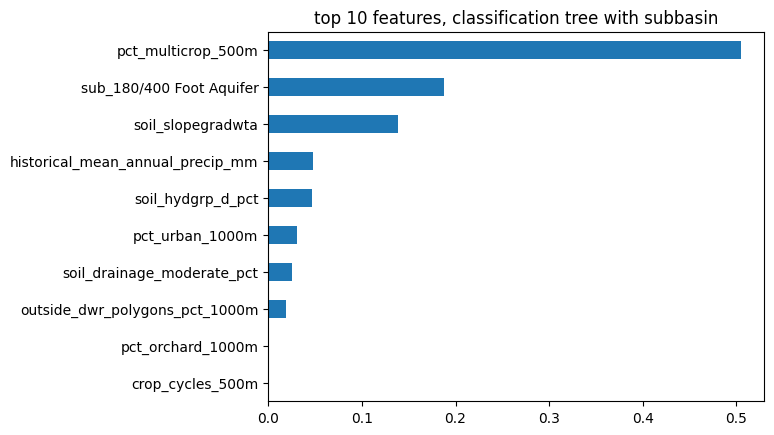

In [13]:
tree_sub = DecisionTreeClassifier(max_depth=best_depth_sub, min_samples_leaf=20, random_state=0)
tree_sub.fit(x_sub, over_tv)

importance_sub = pd.Series(tree_sub.feature_importances_, index=x_sub.columns).sort_values()
importance_sub.tail(10).plot.barh()
plt.title("top 10 features, classification tree with subbasin")
plt.show()

In [14]:
# what-if: the same wells, with no multi-cropped land within 500 m vs 50%
what_if = []
for name in ["180/400 Foot Aquifer", "East Side Aquifer", "Forebay Aquifer", "Upper Valley Aquifer"]:
    wells_here = x_sub[train_val["subbasin"] == name]
    none = wells_here.assign(pct_multicrop_500m=0)
    some = wells_here.assign(pct_multicrop_500m=50)
    what_if.append({"subbasin": name,
                    "risk, no multicrop nearby": tree_sub.predict_proba(none)[:, 1].mean(),
                    "risk, 50% multicrop nearby": tree_sub.predict_proba(some)[:, 1].mean()})

pd.DataFrame(what_if).round(2)

,subbasin,"risk, no multicrop nearby","risk, 50% multicrop nearby"
0,180/400 Foot Aquifer,0.26,0.26
1,East Side Aquifer,0.29,0.65
2,Forebay Aquifer,0.31,0.57
3,Upper Valley Aquifer,0.20,0.47


Swapping elevation for the subbasin makes both trees better (AUC 0.761 to 0.785, R2 0.18 to 0.27) and much easier to explain. The classification tree now splits first on whether there is any multi-cropped land within 500 m, then on whether the well is in the 180/400 Foot Aquifer, then on soil slope. Multi-cropping (land planted two or more times a year, mostly lettuce and other vegetables) gets picked over the vegetable share because the two overlap almost completely.

So the answer to "my land is near a lettuce farm, is my groundwater safe?" depends on which aquifer the well draws from and how intensively the land around it is farmed. Over the East Side Aquifer, the chance of being over 10 mg/L goes from about 29% with no multi-cropped land within 500 m to 65% with some. Over the 180/400 Foot Aquifer it stays about 26% either way, likely because the clay layer slows nitrate from reaching the aquifer. These are patterns the model learned from the data, not proof that the farms cause it, and a single tree only gives a rough yes/no step.